In [20]:
import pandas as pd      
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

In [21]:
df = pd.read_csv("student_performance_dataset.csv")

print("Dataset shape (rows, columns):", df.shape)
display(df.head())

Dataset shape (rows, columns): (500, 6)


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Sleep_Hours,Result
0,4.3,96,64,61,6.5,Pass
1,2.0,90,54,60,6.2,Fail
2,5.1,69,59,91,7.5,Pass
3,5.4,58,75,75,7.3,Pass
4,0.5,39,65,67,5.3,Fail


In [22]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Study_Hours', 'Attendance', 'Previous_Marks', 'Assignment_Score', 'Sleep_Hours', 'Result']


In [23]:
print("\nData types and non-null counts:")
df.info()


Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Study_Hours       500 non-null    float64
 1   Attendance        500 non-null    int64  
 2   Previous_Marks    500 non-null    int64  
 3   Assignment_Score  500 non-null    int64  
 4   Sleep_Hours       500 non-null    float64
 5   Result            500 non-null    str    
dtypes: float64(2), int64(3), str(1)
memory usage: 25.5 KB


In [24]:
print("\nMissing values in each column:")
display(df.isnull().sum())


Missing values in each column:


Study_Hours         0
Attendance          0
Previous_Marks      0
Assignment_Score    0
Sleep_Hours         0
Result              0
dtype: int64

In [25]:

print("\nSummary statistics:")
display(df.describe())


Summary statistics:


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Sleep_Hours
count,500.000000,500.000000,500.00000,500.00000,500.00000
mean,3.779200,77.250000,64.90600,67.34200,6.99680
std,1.626092,12.802003,15.25446,15.72742,1.21579
min,0.000000,35.000000,21.00000,21.00000,3.30000
25%,2.700000,68.750000,55.00000,57.00000,6.20000
50%,3.800000,78.000000,65.00000,68.00000,7.00000
75%,4.800000,86.000000,75.00000,78.00000,7.80000
max,8.800000,100.000000,100.00000,100.00000,10.00000


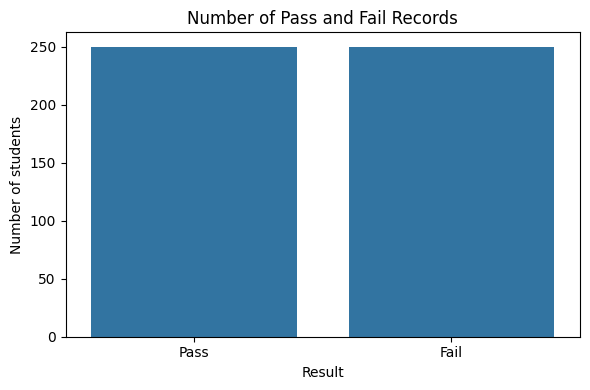

In [26]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Result")
plt.title("Number of Pass and Fail Records")
plt.xlabel("Result")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

In [27]:
print(df["Result"].value_counts())

Result
Pass    250
Fail    250
Name: count, dtype: int64


In [28]:
feature_columns = [
    "Study_Hours",
    "Attendance",
    "Previous_Marks",
    "Assignment_Score",
    "Sleep_Hours"
]


In [29]:
X = df[feature_columns]
y = df["Result"]

In [30]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

In [31]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 400
Testing records: 100


In [32]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling complete.")
print("Scaled training data shape:", X_train_scaled.shape)

Scaling complete.
Scaled training data shape: (400, 5)


In [33]:
ann_model = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=1500,
    early_stopping=True,
    validation_fraction=0.15,
    random_state=RANDOM_STATE
)


ann_model.fit(X_train_scaled, y_train)
print("ANN training completed.")
print("Hidden layer sizes:", ann_model.hidden_layer_sizes)
print("Iterations used:", ann_model.n_iter_)

ANN training completed.
Hidden layer sizes: (16, 8)
Iterations used: 82


In [34]:
y_pred = ann_model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.3f} ({accuracy * 100:.1f}%)")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test accuracy: 0.740 (74.0%)

Classification report:
              precision    recall  f1-score   support

        Fail       0.74      0.74      0.74        50
        Pass       0.74      0.74      0.74        50

    accuracy                           0.74       100
   macro avg       0.74      0.74      0.74       100
weighted avg       0.74      0.74      0.74       100



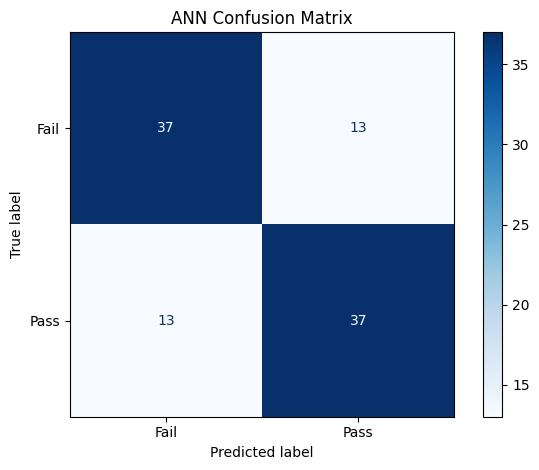

In [35]:
cm = confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("ANN Confusion Matrix")
plt.tight_layout()
plt.show()

In [36]:
new_student = pd.DataFrame([{
    "Study_Hours": 6.0,
    "Attendance": 84,
    "Previous_Marks": 46,
    "Assignment_Score": 80,
    "Sleep_Hours": 8.0
}])

new_student_scaled = scaler.transform(new_student[feature_columns])
predicted_result = ann_model.predict(new_student_scaled)[0]

print("Student:")
display(new_student)
print("ANN predicted result:", predicted_result)

if hasattr(ann_model, "predict_proba"):
    probabilities = ann_model.predict_proba(new_student_scaled)[0]
    probability_table = pd.DataFrame({
        "Class": ann_model.classes_,
        "Model probability": probabilities
    })
    display(probability_table)

Student:


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Sleep_Hours
0,6.0,84,46,80,8.0


ANN predicted result: Pass


,Class,Model probability
0,Fail,0.317273
1,Pass,0.682727
